# I-01: the complete experiment with Run All

Start a **fresh online T4 x2 session**, attach only the matching **i01-source.zip**,
enable Internet and press **Run All**. No old checkpoint, forms, pilot approval
buttons or batch acknowledgements are required. Each ordinary cell performs its
named finite stage and can be run individually.

Run setup, lock the execution plan, qualify the runtime and direct model, then
run three pilots, measured main admission and all ten fixed main batches
(twenty worlds), followed by reports, verified export and worker shutdown.
Models stay resident throughout the research stages. Thinking is not selected.

The fresh study starts at **0/500 physical attempts**; direct-only first attempts
are at most **460**, with at most **28 contingency** attempts. Wrong mathematics
is measured, never an admission threshold. The twelve scalar qualification
controls must be legal. After qualification, ordinary pilot errors, including
prefix, recovery and later controls, remain measured outcomes. Original-team
noncompletion does not veto admission. Invalid actions still deliver nothing.
Durable evidence, runtime and resource gates stop safely.
Every pilot, batch and settled error exports a
cumulative checkpoint. No existing outcome is regenerated on rerun.

The default is a **700-minute planning window** within your reported approximately
12-hour fresh session, leaving a 20-minute margin. This is an estimate, not a
verified provider quota/deadline. Reduce it below if time has already elapsed or
Kaggle shows less remaining. Setup/downloads consume the same fixed window.
Human communication/mechanism review remains retrospective and explicitly pending.


## 1. Fresh-session configuration

Defaults assume a new approximately twelve-hour allocation. Check actual GPU allowance; lower the minutes for any time already elapsed. The evidence note describes an estimate truthfully. Do not copy a previous session deadline or extend the window by rerunning.


In [1]:
RUN_DIR = "/kaggle/working/i01-outcomes-study"
SESSION_REMAINING_MINUTES = 700  # Conservative fresh-session estimate; reduce to actual time left.
SESSION_ALLOWANCE_EVIDENCE = "User reports an approximately 12-hour session; 700-minute fresh-session planning bound, provider quota/deadline not independently verified."


## 2. Verify source and inspect the workspace

Only the matching whole-study source release is accepted. Inventory only; no model loading or inference.


In [2]:
from pathlib import Path
import hashlib, json, shutil, sys, tempfile, zipfile

# Select one exact small source attachment. ZIP and Kaggle-expanded roots work.
SOURCE_BUNDLE = None  # Set only if more than one candidate is attached.
source_candidates = list(Path('/kaggle/input').rglob('i01-source.zip'))
source_candidates += [p.parent for p in Path('/kaggle/input').rglob('source-release.json')]
# Expanded old checkpoints carry their own historical source. They are evidence,
# not candidates for this repaired notebook's active source attachment.
def repaired_source_manifest(path):
    try:
        if path.is_dir():
            manifest = json.loads((path/'source-release.json').read_text())
        else:
            with zipfile.ZipFile(path) as archive:
                manifest = json.loads(archive.read('source-release.json'))
        return manifest if manifest.get('execution_policy') == 'i01-recorded-outcomes-run-all-2026-10-15' and all('recovery/i01/'+name+'.py' in manifest['files'] for name in ('policy','continuation')) else None
    except (OSError, ValueError, KeyError, zipfile.BadZipFile):
        return None
unique_sources = {}
for candidate in source_candidates:
    manifest = repaired_source_manifest(candidate)
    if manifest:
        identity = (manifest.get('git_head'), json.dumps(manifest['files'], sort_keys=True))
        unique_sources.setdefault(identity, candidate)  # Same ZIP/expanded release is one choice.
source_candidates = list(unique_sources.values())
if SOURCE_BUNDLE is None:
    if len(source_candidates) != 1:
        raise RuntimeError(f'Select SOURCE_BUNDLE explicitly; candidates: {source_candidates}')
    SOURCE_BUNDLE = source_candidates[0]
selected_source = Path(SOURCE_BUNDLE)
with tempfile.TemporaryDirectory(prefix='i01-source-', dir='/kaggle/working') as staging_name:
    staging = Path(staging_name)
    if selected_source.is_file():
        with zipfile.ZipFile(selected_source) as source_zip:
            infos = source_zip.infolist()
            if sum(p.file_size for p in infos) > 64 * 2**20 or len({p.filename for p in infos}) != len(infos):
                raise RuntimeError('Source attachment size or duplicate member violation')
            for item in infos:
                p = Path(item.filename)
                if p.is_absolute() or '..' in p.parts or '\\' in item.filename or ':' in item.filename or ((item.external_attr >> 16) & 0o170000) == 0o120000:
                    raise RuntimeError('Unsafe source archive member')
            if source_zip.testzip() is not None:
                raise RuntimeError('Source ZIP integrity failed')
            source_zip.extractall(staging)
    elif selected_source.is_dir():
        if any(p.is_symlink() for p in selected_source.rglob('*')):
            raise RuntimeError('Select an ordinary verified expanded source directory')
        shutil.copytree(selected_source, staging, dirs_exist_ok=True)
    else:
        raise RuntimeError('Missing exact selected source attachment')
    release = json.loads((staging/'source-release.json').read_text())
    if release['format'] != 'i01-online-source-v1':
        raise RuntimeError('Wrong source release format')
    if release.get('execution_policy') != 'i01-recorded-outcomes-run-all-2026-10-15' or not all('recovery/i01/'+name+'.py' in release['files'] for name in ('policy','continuation')):
        raise RuntimeError('This notebook requires the whole-study Run All source packet; preserve old checkpoints and replace the active source attachment.')
    head = release.get('git_head', '')
    if len(head) != 40 or any(c not in '0123456789abcdef' for c in head):
        raise RuntimeError('Invalid source release commit')
    source_root = Path('/kaggle/working') / ('i01-source-' + head[:12])
    for relative, wanted in release['files'].items():
        path = staging/relative
        if not path.is_file() or path.stat().st_size != wanted['bytes'] or hashlib.sha256(path.read_bytes()).hexdigest() != wanted['sha256']:
            raise RuntimeError(f'Source identity failed: {relative}')
        if source_root.exists() and (not (source_root/relative).is_file() or hashlib.sha256((source_root/relative).read_bytes()).hexdigest() != wanted['sha256']):
            raise RuntimeError('Existing source differs; select a fresh session/source directory')
    if not source_root.exists():
        shutil.copytree(staging, source_root)
loaded_source = sys.modules.get('recovery')
if loaded_source is not None and not Path(loaded_source.__file__).resolve().is_relative_to(source_root.resolve()):
    raise RuntimeError('Restart the notebook kernel before using this source release; saved study files are preserved.')
sys.path.insert(0, str(source_root))
from recovery.i01.notebook import Study
if 'study' not in globals():
    study = Study(source_root, run=RUN_DIR)
elif study.source.resolve()!=source_root.resolve() or study.run_dir.resolve()!=Path(RUN_DIR).resolve():
    raise RuntimeError('Finish the current study and restart the kernel before changing source or RUN_DIR; existing study files are preserved.')
study.bootstrap_status()


Workspace,Observed value
Python,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13.3.0]"
System,Linux
Source,/kaggle/working/i01-source-65462e1e5fc6
Study files,/kaggle/working/i01-outcomes-study


Device,Model,UUID,Memory (MiB)
0,Tesla T4,GPU-ed9bad25-b76c-9174-051b-1a8b14ec17e2,15360
1,Tesla T4,GPU-9bd69e6c-b965-32ef-1c1d-4d3aad42f4a0,15360


Storage,Path,Free GiB
scratch,/kaggle/temp/i01,1069.91
working,/kaggle/working,19.5


Session window: unset; preparation is available, model loading requires actual facts in its dedicated cell.
Next: run Install the pinned runtime. Host acceptance still occurs before installation.


## 3. Record the fixed execution window

Record BEFORE installation and downloads. Reruns retain this deadline. No provider assignment, quota or release is inferred from the configured planning window.


In [3]:
study.configure_session(remaining_minutes=SESSION_REMAINING_MINUTES,
    evidence=SESSION_ALLOWANCE_EVIDENCE, basis="planning_estimate");


Measurement,Recorded value
Deadline,2026-10-16T05:20:47.399377+00:00
Evidence,"User reports an approximately 12-hour session; 700-minute fresh-session planning bound, provider quota/deadline not independently verified."
Apply after initialization,Yes


## 4. Install the pinned runtime

Verified pip bootstrap without ensurepip, unchanged pinned dependencies, isolated/headless controller, visible logs/progress. No host startup hooks or unpinned upgrades.


In [4]:
study.install_runtime();


Setup: venv
Setup: download verified pip bootstrap wheel
Setup: bootstrap-pip
Setup: pip-isolation
Setup: dependencies
dependencies: 15s elapsed;   Downloading nvidia_cublas_cu12-12.8.4.1-py3-none-manylinux_2_27_x86_64.whl (594.3 MB)
dependencies: 30s elapsed;   Downloading nvidia_cudnn_cu12-9.19.0.56-py3-none-manylinux_2_27_x86_64.whl (657.9 MB)
dependencies: 45s elapsed;   Downloading nvidia_cufft_cu12-11.3.3.83-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (193.1 MB)
dependencies: 60s elapsed;   Downloading nvidia_cusparselt_cu12-0.7.1-py3-none-manylinux2014_x86_64.whl (287.2 MB)
dependencies: 75s elapsed;   Downloading nvidia_nvshmem_cu12-3.4.5-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (139.1 MB)
dependencies: 90s elapsed;   Downloading torch-2.11.0%2Bcu128-cp313-cp313-manylinux_2_28_x86_64.whl (820.3 MB)
dependencies: 105s elapsed;   Downloading uuid_utils-0.17.1-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (323 kB)
dependencies: 120s elapsed;

Measurement,Recorded value
Interpreter,/kaggle/temp/i01/i01-venv-65462e1e5fc6/bin/python
Source,/kaggle/working/i01-source-65462e1e5fc6
Scratch,/kaggle/temp/i01
Working,/kaggle/working
Hf cache,/kaggle/temp/i01/hf-cache
Setup seconds,228.42080973100008
Model attempts,0


## 5. Start the independent study

New study at zero, no old checkpoint/result import. Repeating this cell reuses the same destination and preserves spending; an old shared campaign cannot be converted.


In [5]:
study.start_new();


Measurement,Recorded value
Deadline,2026-10-16T05:20:47.399377+00:00
Evidence,"User reports an approximately 12-hour session; 700-minute fresh-session planning bound, provider quota/deadline not independently verified."
Apply after initialization,Yes


session: recorded in the stage receipt
Checkpoint action/window: 1,586,668 bytes; integrity passed
window: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip
Checkpoint study-open: 1,586,892 bytes; integrity passed
snapshot: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
Attempt scope,independent-study
Attempts,0
Attempts unknown generated tokens,0
Attempts unknown ready seconds,0
Campaign attempts,0
Campaign attempts unknown ready seconds,0
Campaign generated tokens observed,0
Campaign ready seconds observed,0
Clear minus retain,Unknown / not recorded
Complete case descriptive mean,Unknown / not recorded


Main coverage,Value
Known paired outcomes,0 / 20
Campaign physical attempts,0 / 500 (0 here)
Clear minus retain,Unknown / not recorded
Unknown-outcome bounds,"[-1.0, 1.0]"


Logical slot,Resident,Load receipt
0,No,Not recorded
1,No,Not recorded


Budget,Value
attempt scope,independent-study
attempts,0
campaign attempts,0
contingency,0
in flight,0
local contingency,0
lost spending,"{'resolved': True, 'upper': 0}"
missing prior studies,[]
prior attempts,0
prior spending pending,Unknown / not recorded


## 6. Check implementation and native tokenizer

Focused scripted math/private-view/lifecycle/accounting/durability/archive checks and native token bounds. Zero model attempts.


In [6]:
study.check_implementation();


Checkpoint action/selfcheck: 1,598,939 bytes; integrity passed
selfcheck: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
Environment,scripted temporary DBs; no model loaded
Executed at,2026-10-15T17:44:54.096080+00:00
Model attempts,0
Native tokenizer,Yes
Passed,Yes


Lightweight check,State
native fixture 827/revised 780; duplicates/negative/boundary,Passed
fixed strata/seeds; private views; finality/wait; literal siblings; invalid actions,Passed
raw-before-effects; idempotence; pre-persistence retry; 499/500; backup/ZIP/expanded restore; unknown vs zero,Passed


Native tokenizer: passed


Checkpoint: passed


## 7. Download and verify weights

Pinned model snapshot and actual storage/native file checks. Scratch caches are reused when valid.


In [7]:
study.download_weights();


Setup: weights-command
weights-command: 90s elapsed; Fetching 12 files:  50%|█████     | 6/12 [01:22<01:22, 13.69s/it]
weights-command: 105s elapsed; Verifying pinned native bytes 4/12: model.safetensors-00001-of-00004.safetensors (5,276,436,216 bytes)
weights-command: 120s elapsed; Verifying pinned native bytes 5/12: model.safetensors-00002-of-00004.safetensors (5,335,161,512 bytes)
weights-command: 135s elapsed; Verifying pinned native bytes 5/12: model.safetensors-00002-of-00004.safetensors (5,335,161,512 bytes)
weights-command: 150s elapsed; Verifying pinned native bytes 6/12: model.safetensors-00003-of-00004.safetensors (5,368,717,440 bytes)
weights-command: 165s elapsed; Verifying pinned native bytes 7/12: model.safetensors-00004-of-00004.safetensors (3,325,995,712 bytes)
Checkpoint verified-weights: 1,601,403 bytes; integrity passed
snapshot: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
Model,Qwen/Qwen3.5-9B
Revision,c202236235762e1c871ad0ccb60c8ee5ba337b9a
Snapshot,/kaggle/temp/i01/hf-cache/models--Qwen--Qwen3.5-9B/snapshots/c202236235762e1c871ad0ccb60c8ee5ba337b9a
Native total bytes,19329302519
Weights,Yes
Model attempts,0


## 8. Load both resident T4 workers

Two fixed replicas; concise actual load/device evidence. Loading generates no hidden warmup. Inspection and research stages retain these replicas.


In [8]:
study.load_models();


Working · 60s · Loading weights:  89%|████████▉ | 380/427 [00:46<00:03, 14.00it/s]
Working · 75s · [ERROR] `logits` is part of Qwen3_5CausalLMOutputWithPast.__init__'s signature, but not documented. Make sure to add it to the docstring of the function in /kaggle/temp/i01/i01-venv-65462e1e5fc6/lib/python3.13/site-packages/transformers/models/qwen3_5/modeling_qwen3_5.py.
Working · 105s · Loading weights:  55%|█████▌    | 236/427 [00:25<00:10, 17.74it/s]
Working · 120s · Model load: audit actual tensors, quantization and loading diagnostics
Checkpoint action/load: 1,660,159 bytes; integrity passed
load: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Logical slot,CUDA UUID,Load seconds,Total device GiB
0,ed9bad25-b76c-9174-051b-1a8b14ec17e2,64.1649316380001,14.56
1,9bd69e6c-b965-32ef-1c1d-4d3aad42f4a0,54.863872566000055,14.56


Logical slot,Model / revision,Attention,Recurrent fast path
0,Qwen/Qwen3.5-9B / c202236235762e1c871ad0ccb60c8ee5ba337b9a,recovery_t4_sdpa,No
1,Qwen/Qwen3.5-9B / c202236235762e1c871ad0ccb60c8ee5ba337b9a,recovery_t4_sdpa,No


Pinned text-only NF4/FP16 replicas accepted by the reviewed loader. The loading-only generation profile is not the per-call I-01 profile: direct uses 512 output tokens, temperature 0.7/top-p 0.8/top-k 20.
Known upstream documentation/deprecation messages and optional recurrent-kernel fallback are retained in controller-stderr.log. Full load/tensor inventories remain in sessions.csv and the checkpoint; no runtime upgrade is applied.
Checkpoint: passed


## 9. Lock the complete execution plan

Before the first model call, bind the unchanged manifest/settings, objective checks, ten fixed batches and retrospective review policy. Pilots cannot tune this configuration.


In [9]:
study.plan_execution();


Checkpoint action/plan_execution: 1,726,544 bytes; integrity passed
plan_execution: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
At,2026-10-15T17:49:51.504874+00:00
External download verified,No
Human review,retrospective_pending
Human understanding verified,No
Main admission,three objective pilot passes and adequate measured resources; no settings tuning
Main batches,10
Mode,direct
Pilot admission,fixed scalar qualification; terminal committed pilot phases/controls and intact runtime/resources; ordinary model errors and original completion diagnostic
Policy,i01-recorded-outcomes-run-all-2026-10-15
Useful communication,Unknown / not recorded


Checkpoint: passed


## 10. Check fresh-state readiness

Six A/B/A calls. Cache/numerical/provider faults or unexplained unequal A/B/A stop; no automatic waiver or extra samples.


In [10]:
study.check_readiness();


hardware/state-0-A1 · GPU slot 0 · attempt 1 · campaign 1/500 (1 here)
Raw saved: hardware/state-0-A1 · 14 tokens · 3.9131304960001216 ready-model seconds
hardware/state-0-B · GPU slot 0 · attempt 2 · campaign 2/500 (2 here)
Raw saved: hardware/state-0-B · 16 tokens · 2.27661537899985 ready-model seconds
hardware/state-0-A2 · GPU slot 0 · attempt 3 · campaign 3/500 (3 here)
Raw saved: hardware/state-0-A2 · 14 tokens · 1.790842100999953 ready-model seconds
hardware/state-1-A1 · GPU slot 1 · attempt 1 · campaign 4/500 (4 here)
Raw saved: hardware/state-1-A1 · 14 tokens · 2.8277453229998173 ready-model seconds
hardware/state-1-B · GPU slot 1 · attempt 2 · campaign 5/500 (5 here)
Raw saved: hardware/state-1-B · 16 tokens · 2.22765913499984 ready-model seconds
hardware/state-1-A2 · GPU slot 1 · attempt 3 · campaign 6/500 (6 here)
Raw saved: hardware/state-1-A2 · 14 tokens · 1.7131544569999733 ready-model seconds
Working · 15s · Inference pid=365 device=1 seed=9113091594724103221 phase=decod

Measurement,Recorded value
Equality policy,Diagnostic: unexpected differences require explicit state-isolation review before qualification; no extra samples or decoding changes.
Needs review,No
Passed,Yes


Slot,Probe,Raw visible reply,Finite score steps,Fresh cache
0,A1,"{""message"":null,""submit"":3,""wait"":false}",14,Yes
0,B,"{""message"":null,""submit"":100,""wait"":false}",16,Yes
0,A2,"{""message"":null,""submit"":3,""wait"":false}",14,Yes
1,A1,"{""message"":null,""submit"":3,""wait"":false}",14,Yes
1,B,"{""message"":null,""submit"":100,""wait"":false}",16,Yes
1,A2,"{""message"":null,""submit"":3,""wait"":false}",14,Yes


A/B/A equal by slot: [True, True]; Diagnostic: unexpected differences require explicit state-isolation review before qualification; no extra samples or decoding changes.


Checkpoint: passed


## 11. Qualify direct protocol

Twelve fixed original/revised controls. All twelve must be committed and protocol-valid. Wrong scalar answers alone pass protocol admission and remain visible outcomes.


In [11]:
study.qualify_direct();


qualification-00/control-original-direct · GPU slot 0 · attempt 4 · campaign 7/500 (7 here)
Raw saved: qualification-00/control-original-direct · 16 tokens · 2.330217538999932 ready-model seconds
qualification-00/control-revised-direct · GPU slot 0 · attempt 5 · campaign 8/500 (8 here)
Raw saved: qualification-00/control-revised-direct · 16 tokens · 2.016708554999923 ready-model seconds
qualification-01/control-original-direct · GPU slot 1 · attempt 4 · campaign 9/500 (9 here)
Raw saved: qualification-01/control-original-direct · 16 tokens · 2.6576872719999756 ready-model seconds
qualification-01/control-revised-direct · GPU slot 1 · attempt 5 · campaign 10/500 (10 here)
Raw saved: qualification-01/control-revised-direct · 16 tokens · 2.1023488839998663 ready-model seconds
qualification-02/control-original-direct · GPU slot 0 · attempt 6 · campaign 11/500 (11 here)
Raw saved: qualification-02/control-original-direct · 17 tokens · 2.574335818999998 ready-model seconds
qualification-02/c

Measurement,Recorded value
Admitted,12
Attempts unknown effort,0
Committed,12
Correct,10
Generated tokens observed,193
Mode,direct
Passed,Yes
Physical attempts,12
Planned,12
Policy,i01-direct-protocol-2026-10-15


Protocol qualification: 12/12 committed; 0 invalid actions; current eligible: True. Mathematical diagnostic: 10/12.
Original saved gate decision (unchanged): True; rule i01-direct-protocol-2026-10-15


Failed call,Truth,Submission,Error
qualification-03/control-original-direct,951,788,wrong scalar
qualification-03/control-revised-direct,920,788,wrong scalar


Checkpoint: passed


## 12. Inspect qualification

Every planned direct control, truth/submission, validity, correctness, effort and failure-first raw audit. Complete raw evidence is downloadable.


In [12]:
study.inspect_qualification(mode="direct");


Scientific gate: pending; no recorded blocking failure


Mode,Committed/planned,Correct,Wrong scalar,Invalid,Unexecuted,Current eligible,Historical passed
direct,12/12,10,2,0,0,Yes,Yes


Call,Truth,Submission,Valid,Correct,Error,Tokens,Ready seconds
qualification-00/control-original-direct,950,950,Yes,1,Unknown / not recorded,16,2.330217538999932
qualification-00/control-revised-direct,921,921,Yes,1,Unknown / not recorded,16,2.016708554999923
qualification-01/control-original-direct,999,999,Yes,1,Unknown / not recorded,16,2.6576872719999756
qualification-01/control-revised-direct,931,931,Yes,1,Unknown / not recorded,16,2.1023488839998663
qualification-02/control-original-direct,1000,1000,Yes,1,Unknown / not recorded,17,2.574335818999998
qualification-02/control-revised-direct,981,981,Yes,1,Unknown / not recorded,16,2.0284269019998646
qualification-03/control-original-direct,951,788,Yes,0,Unknown / not recorded,16,2.2077921800000695
qualification-03/control-revised-direct,920,788,Yes,0,Unknown / not recorded,16,2.116515100000015
qualification-04/control-original-direct,956,956,Yes,1,Unknown / not recorded,16,2.4590995640000983
qualification-04/control-revised-direct,918,918,Yes,1,Unknown / not recorded,16,2.0331257269999696


Main paired coverage: 0/20 intended worlds. Campaign: 18/500 physical attempts (18 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


Admission resource,Value
Remaining attempt allowance,482
Contingency including bounded lost spending,0
Lost spending evidence,"{'resolved': True, 'upper': 0}"
Remaining session seconds,41404.060461


Exact failed call,Phase,Reason,Admission blocking


Showing 3/12 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## 13. Check full headroom

Two full-input/full-output diagnostic probes, one per current load. Require at least 1.5 GiB measured free headroom on each T4.


In [13]:
study.check_headroom();


hardware/envelope-direct-0 · GPU slot 0 · attempt 10 · campaign 19/500 (19 here)
Working · 15s · Inference pid=351 device=0 seed=3554240822569505675 phase=decode elapsed=13.3s input=8192/8192 decode=0/512 peak_reserved_mib=7824.0
Working · 30s · Inference pid=351 device=0 seed=3554240822569505675 phase=decode elapsed=28.3s input=8192/8192 decode=137/512 peak_reserved_mib=7824.0
Working · 45s · Inference pid=351 device=0 seed=3554240822569505675 phase=decode elapsed=43.3s input=8192/8192 decode=274/512 peak_reserved_mib=7824.0
Working · 60s · Inference pid=351 device=0 seed=3554240822569505675 phase=decode elapsed=58.3s input=8192/8192 decode=414/512 peak_reserved_mib=7824.0
Raw saved: hardware/envelope-direct-0 · 512 tokens · 68.96988406799983 ready-model seconds
hardware/envelope-direct-1 · GPU slot 1 · attempt 10 · campaign 20/500 (20 here)
Working · 75s · Inference pid=365 device=1 seed=6895241862355992459 phase=prefill elapsed=0.0s input=0/8192 decode=0/512 peak_reserved_mib=7540.0

Measurement,Recorded value
Mode,direct
Passed,Yes
Reload,No
Session,a7bb7845-cf04-4efd-9b68-f74b9595cfaa


Slot,Generated tokens,Observed free headroom (GiB),Failure
0,512,6.788,None recorded
1,512,6.784,None recorded


Checkpoint: passed


## Run pilot 1

Pilot 1 only: prefix, literal retain/clear siblings and original/revised controls, at most twenty first attempts. Conversation and cumulative checkpoint appear automatically. No outcome-based replacement or extra seed.


In [14]:
study.run_pilot(1);


pilot-00/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 11 · campaign 21/500 (21 here)
Raw saved: pilot-00/prefix/agent-0/invocation-0 · 16 tokens · 2.6446261020000748 ready-model seconds
pilot-00 / prefix / agent 0: {'message': None, 'submit': None, 'wait': True} · continuing
pilot-00/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 12 · campaign 22/500 (22 here)
Raw saved: pilot-00/prefix/agent-1/invocation-0 · 78 tokens · 9.197603716000003 ready-model seconds
pilot-00 / prefix / agent 1: {'message': 'I am Agent 1. My shard contains 21 integers. I will scan for the maximum value in my shard and coordinate with Agent 2 to determine the global maximum. I will submit my candidate for the global maximum if I believe it is the highest value found so far across both shards.', 'submit': 923, 'wait': False} · continuing
pilot-00/prefix/agent-0/invocation-1 · GPU slot 0 · attempt 13 · campaign 23/500 (23 here)
Working · 15s · Inference pid=351 device=0 seed=1023110753385749315 phase=dec

Measurement,Recorded value
Pilot,1
World,pilot-00


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Original control,Revised control
pilot-00,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct,Correct


Main paired coverage: 0/20 intended worlds. Campaign: 32/500 physical attempts (32 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 1 · pilot-00/retain/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action


Agent 0 · pilot-00/clear/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action


Agent 0 · pilot-00/clear/agent-0/invocation-1 · waiting


Exact failed call,Phase,Reason,Admission blocking
pilot-00/retain/agent-1/invocation-0,retain,wait_requires_null_message_and_submit,No
pilot-00/clear/agent-0/invocation-0,clear,wait_requires_null_message_and_submit,No


Showing 6/12 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Check pilot 1 automatically

Require every scheduled episode/control to have terminal committed evidence, reconciled spending and intact runtime/export evidence. All ordinary prefix/recovery/control mistakes and terminal noncompletion are measured outcomes after scalar qualification. Compliance and original-team completion are shown separately. Useful communication remains unreviewed.


In [15]:
study.check_pilot(1);


Checkpoint action/check_pilot: 1,912,862 bytes; integrity passed
check_pilot: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
Control protocol errors,0
Human review,retrospective_pending
Original messages,2
Original team completed,Yes
Passed,Yes
Pilot,1
Policy,i01-recorded-outcomes-run-all-2026-10-15
Prefix protocol errors,0
Protocol errors,2
Recorded calls,12


Pilot admission,Value
Policy,i01-recorded-outcomes-run-all-2026-10-15
Evidence admitted,Yes
Original team completed (diagnostic),Yes
Invalid prefix / recovery / controls,0 / 2 / 0


Blocking prerequisite,Passed
committed_calls,Yes
every_episode_has_calls,Yes
inspectable_checkpoint,Yes
reconciled_spending,Yes
runtime_integrity,Yes
terminal_evidence,Yes


Checkpoint: passed


## Run pilot 2

Pilot 2 only: prefix, literal retain/clear siblings and original/revised controls, at most twenty first attempts. Conversation and cumulative checkpoint appear automatically. No outcome-based replacement or extra seed.


In [16]:
study.run_pilot(2);


pilot-01/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 11 · campaign 33/500 (33 here)
Raw saved: pilot-01/prefix/agent-0/invocation-0 · 16 tokens · 2.663763280000012 ready-model seconds
pilot-01 / prefix / agent 0: {'message': None, 'submit': None, 'wait': True} · continuing
pilot-01/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 12 · campaign 34/500 (34 here)
Working · 15s · Inference pid=365 device=1 seed=8024261074218990468 phase=decode elapsed=0.9s input=336/336 decode=0/512 peak_reserved_mib=7828.0
Raw saved: pilot-01/prefix/agent-1/invocation-0 · 149 tokens · 17.15699809800003 ready-model seconds
pilot-01 / prefix / agent 1: malformed_action · continuing
pilot-01/prefix/agent-1/invocation-1 · GPU slot 1 · attempt 13 · campaign 35/500 (35 here)
Raw saved: pilot-01/prefix/agent-1/invocation-1 · 39 tokens · 5.117367332999947 ready-model seconds
pilot-01 / prefix / agent 1: {'message': 'I see your shard contains -998. I will submit 985 as my maximum.', 'submit': 985, 'wait':

Measurement,Recorded value
Pilot,2
World,pilot-01


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Original control,Revised control
pilot-01,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct,Correct


Main paired coverage: 0/20 intended worlds. Campaign: 43/500 physical attempts (43 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 0 · pilot-01/prefix/agent-0/invocation-0 · waiting
Agent 1 · pilot-01/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action


Agent 0 · pilot-01/prefix/agent-0/invocation-1 · no public message


Agent 0 · pilot-01/clear/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action


Exact failed call,Phase,Reason,Admission blocking
pilot-01/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
pilot-01/clear/agent-0/invocation-0,clear,wait_requires_null_message_and_submit,No


Showing 6/11 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Check pilot 2 automatically

Require every scheduled episode/control to have terminal committed evidence, reconciled spending and intact runtime/export evidence. All ordinary prefix/recovery/control mistakes and terminal noncompletion are measured outcomes after scalar qualification. Compliance and original-team completion are shown separately. Useful communication remains unreviewed.


In [17]:
study.check_pilot(2);


Checkpoint action/check_pilot: 1,961,243 bytes; integrity passed
check_pilot: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
Control protocol errors,0
Human review,retrospective_pending
Original messages,1
Original team completed,Yes
Passed,Yes
Pilot,2
Policy,i01-recorded-outcomes-run-all-2026-10-15
Prefix protocol errors,1
Protocol errors,2
Recorded calls,11


Pilot admission,Value
Policy,i01-recorded-outcomes-run-all-2026-10-15
Evidence admitted,Yes
Original team completed (diagnostic),Yes
Invalid prefix / recovery / controls,1 / 1 / 0


Blocking prerequisite,Passed
committed_calls,Yes
every_episode_has_calls,Yes
inspectable_checkpoint,Yes
reconciled_spending,Yes
runtime_integrity,Yes
terminal_evidence,Yes


Checkpoint: passed


## Run pilot 3

Pilot 3 only: prefix, literal retain/clear siblings and original/revised controls, at most twenty first attempts. Conversation and cumulative checkpoint appear automatically. No outcome-based replacement or extra seed.


In [18]:
study.run_pilot(3);


pilot-02/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 23 · campaign 44/500 (44 here)
Raw saved: pilot-02/prefix/agent-1/invocation-0 · 34 tokens · 4.222013563000019 ready-model seconds
pilot-02 / prefix / agent 1: malformed_action · continuing
pilot-02/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 24 · campaign 45/500 (45 here)
Working · 15s · Inference pid=351 device=0 seed=7049442019502801809 phase=decode elapsed=1.0s input=336/336 decode=0/512 peak_reserved_mib=7832.0
Raw saved: pilot-02/prefix/agent-0/invocation-0 · 147 tokens · 16.757747720999987 ready-model seconds
pilot-02 / prefix / agent 0: malformed_action · continuing
pilot-02/prefix/agent-1/invocation-1 · GPU slot 0 · attempt 25 · campaign 46/500 (46 here)
Working · 30s · Inference pid=351 device=0 seed=1303939391147026415 phase=decode elapsed=1.0s input=346/346 decode=0/512 peak_reserved_mib=7832.0
Raw saved: pilot-02/prefix/agent-1/invocation-1 · 200 tokens · 22.168335626999806 ready-model seconds
pilot-02 / pr

Measurement,Recorded value
Pilot,3
World,pilot-02


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Original control,Revised control
pilot-02,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct,Correct


Main paired coverage: 0/20 intended worlds. Campaign: 55/500 physical attempts (55 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 1 · pilot-02/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 0 · pilot-02/prefix/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 1 · pilot-02/prefix/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action


Agent 1 · pilot-02/retain/agent-1/invocation-0 · waiting


Agent 1 · pilot-02/retain/agent-1/invocation-1 · no public message


Exact failed call,Phase,Reason,Admission blocking
pilot-02/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
pilot-02/prefix/agent-0/invocation-0,prefix,wait_requires_null_message_and_submit,No
pilot-02/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No


Showing 6/12 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Check pilot 3 automatically

Require every scheduled episode/control to have terminal committed evidence, reconciled spending and intact runtime/export evidence. All ordinary prefix/recovery/control mistakes and terminal noncompletion are measured outcomes after scalar qualification. Compliance and original-team completion are shown separately. Useful communication remains unreviewed.


In [19]:
study.check_pilot(3);


Checkpoint action/check_pilot: 2,006,611 bytes; integrity passed
check_pilot: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
Control protocol errors,0
Human review,retrospective_pending
Original messages,2
Original team completed,Yes
Passed,Yes
Pilot,3
Policy,i01-recorded-outcomes-run-all-2026-10-15
Prefix protocol errors,3
Protocol errors,3
Recorded calls,12


Pilot admission,Value
Policy,i01-recorded-outcomes-run-all-2026-10-15
Evidence admitted,Yes
Original team completed (diagnostic),Yes
Invalid prefix / recovery / controls,3 / 0 / 0


Blocking prerequisite,Passed
committed_calls,Yes
every_episode_has_calls,Yes
inspectable_checkpoint,Yes
reconciled_spending,Yes
runtime_integrity,Yes
terminal_evidence,Yes


Checkpoint: passed


## Admit the unchanged main experiment

All three objective pilot checks must pass. Record measured attempt/time feasibility under the already locked configuration. No human approval is invented and no pilot-driven tuning occurs. An inadequate forecast stops with a partial checkpoint.


In [20]:
study.admit_main();


Checkpoint action/admit_main: 2,152,595 bytes; integrity passed
admit_main: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
At,2026-10-15T17:57:54.267336+00:00
Execution policy,i01-recorded-outcomes-run-all-2026-10-15
Human review,retrospective_pending
Implementation transition,Unknown / not recorded
Mode,direct
Notes,Automatic main resource admission under the precommitted Run All plan; human communication review remains pending.
Qualification policy,i01-direct-protocol-2026-10-15


Checkpoint: passed


## Main batch 1/10: worlds 00 and 01

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [21]:
study.run_main_batch(1);


main-00/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 35 · campaign 56/500 (56 here)
main-01/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 22 · campaign 57/500 (57 here)
Raw saved: main-01/prefix/agent-0/invocation-0 · 16 tokens · 2.740961255000002 ready-model seconds
main-01 / prefix / agent 0: {'message': None, 'submit': None, 'wait': True} · continuing
main-01/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 23 · campaign 58/500 (58 here)
Raw saved: main-00/prefix/agent-0/invocation-0 · 35 tokens · 5.021326467000108 ready-model seconds
main-00 / prefix / agent 0: malformed_action · continuing
main-00/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 36 · campaign 59/500 (59 here)
Raw saved: main-00/prefix/agent-1/invocation-0 · 16 tokens · 2.623836925999967 ready-model seconds
main-00 / prefix / agent 1: {'message': None, 'submit': None, 'wait': True} · continuing
main-00/prefix/agent-0/invocation-1 · GPU slot 0 · attempt 37 · campaign 60/500 (60 here)
Raw saved: main-0

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-00+main-01
Number,1
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-00,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-01,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 2/20 intended worlds. Campaign: 75/500 physical attempts (75 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 0 · main-00/clear/agent-0/invocation-0 · no public message


Agent 0 · main-01/prefix/agent-0/invocation-0 · waiting
Agent 1 · main-01/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-01/prefix/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-01/prefix/agent-1/invocation-2 · invalid/failed action; no message delivered: malformed_action


Agent 1 · main-01/retain/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-01/retain/agent-1/invocation-1 · no public message


Exact failed call,Phase,Reason,Admission blocking
main-00/prefix/agent-0/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-00/prefix/agent-0/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-01/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-01/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-01/prefix/agent-1/invocation-2,prefix,wait_requires_null_message_and_submit,No
main-01/retain/agent-1/invocation-0,retain,empty_nonwaiting_action,No


Showing 6/20 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 2/10: worlds 02 and 03

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [22]:
study.run_main_batch(2);


main-02/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 45 · campaign 76/500 (76 here)
main-03/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 32 · campaign 77/500 (77 here)
Raw saved: main-02/prefix/agent-0/invocation-0 · 16 tokens · 2.5021519240001453 ready-model seconds
main-02 / prefix / agent 0: {'message': None, 'submit': None, 'wait': True} · continuing
main-02/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 46 · campaign 78/500 (78 here)
Raw saved: main-02/prefix/agent-1/invocation-0 · 41 tokens · 5.333300381999834 ready-model seconds
main-02 / prefix / agent 1: malformed_action · continuing
main-02/prefix/agent-1/invocation-1 · GPU slot 0 · attempt 47 · campaign 79/500 (79 here)
Raw saved: main-03/prefix/agent-0/invocation-0 · 87 tokens · 10.543681550999963 ready-model seconds
main-03 / prefix / agent 0: {'message': "I am Agent 0. My shard contains 20 integers. I need to find the maximum value in my shard and compare it with Agent 1's maximum. My shard's maximum is 99

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-02+main-03
Number,2
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-02,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-03,Correct,Unsuccessful (recorded),Correct,Unsuccessful (recorded)


Main paired coverage: 4/20 intended worlds. Campaign: 95/500 physical attempts (95 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 0 · main-02/prefix/agent-0/invocation-0 · waiting
Agent 1 · main-02/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-02/prefix/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-02/prefix/agent-1/invocation-2 · waiting


Agent 1 · main-03/prefix/agent-1/invocation-1 · no public message


Agent 0 · main-03/clear/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action


Exact failed call,Phase,Reason,Admission blocking
main-02/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-02/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-03/clear/agent-0/invocation-0,clear,wait_requires_null_message_and_submit,No


Showing 6/20 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 3/10: worlds 04 and 05

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [23]:
study.run_main_batch(3);


main-04/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 54 · campaign 96/500 (96 here)
main-05/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 43 · campaign 97/500 (97 here)
Working · 15s · Inference pid=365 device=1 seed=7259646355533685262 phase=decode elapsed=0.8s input=339/339 decode=0/512 peak_reserved_mib=7832.0
Raw saved: main-04/prefix/agent-0/invocation-0 · 150 tokens · 17.685654999000008 ready-model seconds
main-04 / prefix / agent 0: malformed_action · continuing
main-04/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 55 · campaign 98/500 (98 here)
Raw saved: main-05/prefix/agent-1/invocation-0 · 154 tokens · 17.8302299689999 ready-model seconds
main-05 / prefix / agent 1: malformed_action · continuing
main-05/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 44 · campaign 99/500 (99 here)
Raw saved: main-04/prefix/agent-1/invocation-0 · 16 tokens · 2.452942093000047 ready-model seconds
main-04 / prefix / agent 1: {'message': None, 'submit': None, 'wait': True} · c

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-04+main-05
Number,3
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-04,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-05,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 6/20 intended worlds. Campaign: 116/500 physical attempts (116 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 1 · main-05/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-05/prefix/agent-0/invocation-0 · waiting
Agent 1 · main-05/prefix/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-05/prefix/agent-1/invocation-2 · invalid/failed action; no message delivered: malformed_action


Agent 1 · main-05/clear/agent-1/invocation-0 · waiting


Agent 1 · main-05/clear/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-05/clear/agent-1/invocation-2 · waiting


Exact failed call,Phase,Reason,Admission blocking
main-04/prefix/agent-0/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-04/prefix/agent-0/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-04/prefix/agent-0/invocation-2,prefix,wait_requires_null_message_and_submit,No
main-04/retain/agent-0/invocation-0,retain,wait_requires_null_message_and_submit,No
main-05/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-05/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-05/prefix/agent-1/invocation-2,prefix,wait_requires_null_message_and_submit,No
main-05/clear/agent-1/invocation-1,clear,empty_nonwaiting_action,No


Showing 6/21 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 4/10: worlds 06 and 07

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [24]:
study.run_main_batch(4);


main-06/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 64 · campaign 117/500 (117 here)
main-07/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 54 · campaign 118/500 (118 here)
Raw saved: main-06/prefix/agent-1/invocation-0 · 16 tokens · 2.8313040699999874 ready-model seconds
main-06 / prefix / agent 1: {'message': None, 'submit': None, 'wait': True} · continuing
main-06/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 65 · campaign 119/500 (119 here)
Raw saved: main-06/prefix/agent-0/invocation-0 · 16 tokens · 2.4306549829998403 ready-model seconds
main-06 / prefix / agent 0: {'message': None, 'submit': None, 'wait': True} · waiting_deadlock
main-06/retain/agent-1/invocation-0 · GPU slot 0 · attempt 66 · campaign 120/500 (120 here)
Raw saved: main-06/retain/agent-1/invocation-0 · 55 tokens · 7.203204806000031 ready-model seconds
main-06 / retain / agent 1: {'message': "Partner's shard (owner 0) has max 926. My shard (owner 1) has max 926. Global max is 926.", 'submit': 926, '

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-06+main-07
Number,4
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-06,Unsuccessful (recorded),Correct,Unsuccessful (recorded),Correct
main-07,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded)


Main paired coverage: 8/20 intended worlds. Campaign: 133/500 physical attempts (133 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 1 · main-06/prefix/agent-1/invocation-0 · waiting
Agent 0 · main-06/prefix/agent-0/invocation-0 · waiting


Agent 1 · main-06/clear/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-06/clear/agent-0/invocation-0 · no public message


Agent 1 · main-07/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-07/prefix/agent-0/invocation-0 · waiting
Agent 1 · main-07/prefix/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-07/prefix/agent-1/invocation-2 · invalid/failed action; no message delivered: malformed_action


Exact failed call,Phase,Reason,Admission blocking
main-06/clear/agent-1/invocation-0,clear,wait_requires_null_message_and_submit,No
main-07/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-07/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-07/prefix/agent-1/invocation-2,prefix,wait_requires_null_message_and_submit,No


Showing 6/17 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 5/10: worlds 08 and 09

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [25]:
study.run_main_batch(5);


main-08/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 72 · campaign 134/500 (134 here)
main-09/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 63 · campaign 135/500 (135 here)
Raw saved: main-09/prefix/agent-1/invocation-0 · 16 tokens · 2.7015507539999817 ready-model seconds
main-09 / prefix / agent 1: {'message': None, 'submit': None, 'wait': True} · continuing
main-09/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 64 · campaign 136/500 (136 here)
Raw saved: main-08/prefix/agent-1/invocation-0 · 35 tokens · 4.573055646999819 ready-model seconds
main-08 / prefix / agent 1: malformed_action · continuing
main-08/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 73 · campaign 137/500 (137 here)
Raw saved: main-09/prefix/agent-0/invocation-0 · 29 tokens · 3.826342179000221 ready-model seconds
main-09 / prefix / agent 0: malformed_action · continuing
main-09/prefix/agent-0/invocation-1 · GPU slot 1 · attempt 65 · campaign 138/500 (138 here)
Raw saved: main-08/prefix/agent-0/inv

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-08+main-09
Number,5
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-08,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-09,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded)


Main paired coverage: 10/20 intended worlds. Campaign: 153/500 physical attempts (153 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 1 · main-09/prefix/agent-1/invocation-0 · waiting
Agent 0 · main-09/prefix/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-09/prefix/agent-0/invocation-1 · invalid/failed action; no message delivered: malformed_action


Agent 1 · main-09/prefix/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action


Agent 0 · main-09/retain/agent-0/invocation-0 · no public message


Exact failed call,Phase,Reason,Admission blocking
main-08/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-09/prefix/agent-0/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-09/prefix/agent-0/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-09/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No


Showing 6/20 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 6/10: worlds 10 and 11

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [26]:
study.run_main_batch(6);


main-10/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 81 · campaign 154/500 (154 here)
main-11/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 74 · campaign 155/500 (155 here)
Raw saved: main-11/prefix/agent-0/invocation-0 · 16 tokens · 2.444351144999928 ready-model seconds
main-11 / prefix / agent 0: {'message': None, 'submit': None, 'wait': True} · continuing
main-11/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 75 · campaign 156/500 (156 here)
Raw saved: main-11/prefix/agent-1/invocation-0 · 34 tokens · 4.697895914999663 ready-model seconds
main-11 / prefix / agent 1: malformed_action · continuing
main-11/prefix/agent-1/invocation-1 · GPU slot 1 · attempt 76 · campaign 157/500 (157 here)
Raw saved: main-10/prefix/agent-0/invocation-0 · 68 tokens · 8.139697361999879 ready-model seconds
main-10 / prefix / agent 0: {'message': 'I see your shard has 20 integers. The maximum in my shard is 758. I will propose 758 as the global maximum. If your shard contains a larger value, 

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-10+main-11
Number,6
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-10,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded)
main-11,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 12/20 intended worlds. Campaign: 173/500 physical attempts (173 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 0 · main-10/clear/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action


Agent 0 · main-10/clear/agent-0/invocation-1 · invalid/failed action; no message delivered: malformed_action


Agent 0 · main-11/prefix/agent-0/invocation-0 · waiting
Agent 1 · main-11/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-11/prefix/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action


Exact failed call,Phase,Reason,Admission blocking
main-10/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-10/clear/agent-0/invocation-0,clear,wait_requires_null_message_and_submit,No
main-10/clear/agent-0/invocation-1,clear,wait_requires_null_message_and_submit,No
main-11/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-11/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No


Showing 6/20 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 7/10: worlds 12 and 13

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [27]:
study.run_main_batch(7);


main-13/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 84 · campaign 174/500 (174 here)
main-12/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 91 · campaign 175/500 (175 here)
Raw saved: main-12/prefix/agent-0/invocation-0 · 16 tokens · 2.42907574200035 ready-model seconds
main-12 / prefix / agent 0: {'message': None, 'submit': None, 'wait': True} · continuing
main-12/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 92 · campaign 176/500 (176 here)
Raw saved: main-13/prefix/agent-0/invocation-0 · 38 tokens · 4.873470473999987 ready-model seconds
main-13 / prefix / agent 0: {'message': 'Partner finished: False. No submissions received yet. I will submit my shard to propose a candidate.', 'submit': 737, 'wait': False} · continuing
Raw saved: main-12/prefix/agent-1/invocation-0 · 16 tokens · 2.4067276220002896 ready-model seconds
main-12 / prefix / agent 1: {'message': None, 'submit': None, 'wait': True} · waiting_deadlock
main-13/prefix/agent-1/invocation-0 · GPU slot 1 · attem

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-12+main-13
Number,7
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-12,Unsuccessful (recorded),Correct,Correct,Correct
main-13,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 14/20 intended worlds. Campaign: 187/500 physical attempts (187 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


Admission resource,Value
Remaining attempt allowance,313
Contingency including bounded lost spending,0
Lost spending evidence,"{'resolved': True, 'upper': 0}"
Remaining session seconds,40350.510331


World,Phase,Calls,Generated tokens,Ready-model seconds,Messages
main-12,prefix,2,32,4.83580336400064,0
main-12,retain,2,78,10.331761865000317,2
main-12,clear,2,78,10.150658473000021,2
main-13,prefix,2,76,10.112985596999806,2
main-13,retain,2,76,10.167345235000084,2
main-13,clear,2,106,13.372943826999744,2


Agent 0 · main-12/prefix/agent-0/invocation-0 · waiting
Agent 1 · main-12/prefix/agent-1/invocation-0 · waiting


Exact failed call,Phase,Reason,Admission blocking


Showing 6/14 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 8/10: worlds 14 and 15

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [28]:
study.run_main_batch(8);


main-14/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 98 · campaign 188/500 (188 here)
main-15/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 91 · campaign 189/500 (189 here)
Raw saved: main-15/prefix/agent-1/invocation-0 · 47 tokens · 5.977945554000144 ready-model seconds
main-15 / prefix / agent 1: malformed_action · continuing
main-15/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 92 · campaign 190/500 (190 here)
Raw saved: main-15/prefix/agent-0/invocation-0 · 44 tokens · 5.5987969650000196 ready-model seconds
main-15 / prefix / agent 0: malformed_action · continuing
main-15/prefix/agent-1/invocation-1 · GPU slot 1 · attempt 93 · campaign 191/500 (191 here)
Working · 15s · Inference pid=365 device=1 seed=9210302312644362371 phase=decode elapsed=0.7s input=347/347 decode=0/512 peak_reserved_mib=7834.0
Raw saved: main-14/prefix/agent-0/invocation-0 · 141 tokens · 16.382450163999692 ready-model seconds
main-14 / prefix / agent 0: malformed_action · continuing
main-14/pref

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-14+main-15
Number,8
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-14,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-15,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 16/20 intended worlds. Campaign: 211/500 physical attempts (211 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 0 · main-14/clear/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action


Agent 1 · main-15/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-15/prefix/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-15/prefix/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-15/prefix/agent-0/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-15/prefix/agent-1/invocation-2 · no public message
Agent 0 · main-15/prefix/agent-0/invocation-2 · no public message


Agent 1 · main-15/retain/agent-1/invocation-0 · no public message


Exact failed call,Phase,Reason,Admission blocking
main-14/prefix/agent-0/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-14/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-14/prefix/agent-0/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-14/prefix/agent-0/invocation-2,prefix,wait_requires_null_message_and_submit,No
main-14/clear/agent-0/invocation-0,clear,wait_requires_null_message_and_submit,No
main-15/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-15/prefix/agent-0/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-15/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-15/prefix/agent-0/invocation-1,prefix,wait_requires_null_message_and_submit,No


Showing 6/24 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 9/10: worlds 16 and 17

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [29]:
study.run_main_batch(9);


main-17/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 102 · campaign 212/500 (212 here)
main-16/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 111 · campaign 213/500 (213 here)
Working · 15s · Inference pid=365 device=1 seed=1558207476444573364 phase=decode elapsed=0.8s input=338/338 decode=0/512 peak_reserved_mib=7834.0
Raw saved: main-17/prefix/agent-1/invocation-0 · 146 tokens · 17.14331396899979 ready-model seconds
main-17 / prefix / agent 1: malformed_action · continuing
main-17/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 103 · campaign 214/500 (214 here)
Raw saved: main-16/prefix/agent-1/invocation-0 · 152 tokens · 17.37756543100022 ready-model seconds
main-16 / prefix / agent 1: {'message': 'I see your shard contains 20 integers. I will scan for the maximum. My shard: [-260, 788, 919, -221, 629, -63, 334, -319, 574, 752, 792, -664, 880, -864, 753, -803, 297, -54, 895, 652]. The maximum is 919. I will submit 919.', 'submit': 919, 'wait': False} · continuing
main-1

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-16+main-17
Number,9
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-16,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded)
main-17,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 18/20 intended worlds. Campaign: 227/500 physical attempts (227 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


Admission resource,Value
Remaining attempt allowance,273
Contingency including bounded lost spending,0
Lost spending evidence,"{'resolved': True, 'upper': 0}"
Remaining session seconds,40090.420996


World,Phase,Calls,Generated tokens,Ready-model seconds,Messages
main-16,prefix,2,303,35.52111608200039,2
main-16,retain,2,303,36.8465388149998,2
main-16,clear,2,338,39.08526874200015,2
main-17,prefix,4,356,42.75290729000017,2
main-17,retain,2,64,9.264408575999823,2
main-17,clear,2,193,23.592079619999822,2


Agent 1 · main-17/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-17/prefix/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action


Exact failed call,Phase,Reason,Admission blocking
main-17/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-17/prefix/agent-0/invocation-0,prefix,wait_requires_null_message_and_submit,No


Showing 6/16 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 10/10: worlds 18 and 19

Execute these two predetermined worlds, one per logical slot, at most 38 first attempts. Commit all terminal outcomes, show conversations and export before the next cell. Wrong/invalid recorded main replies remain measured failures. Rerunning this numbered cell never advances another batch or resamples.


In [30]:
study.run_main_batch(10);


main-18/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 118 · campaign 228/500 (228 here)
main-19/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 111 · campaign 229/500 (229 here)
Raw saved: main-18/prefix/agent-1/invocation-0 · 35 tokens · 4.783721139000136 ready-model seconds
main-18 / prefix / agent 1: malformed_action · continuing
main-18/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 119 · campaign 230/500 (230 here)
Raw saved: main-19/prefix/agent-1/invocation-0 · 60 tokens · 7.585079253999993 ready-model seconds
main-19 / prefix / agent 1: malformed_action · continuing
main-19/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 112 · campaign 231/500 (231 here)
Raw saved: main-19/prefix/agent-0/invocation-0 · 33 tokens · 4.43153384299967 ready-model seconds
main-19 / prefix / agent 0: malformed_action · continuing
main-19/prefix/agent-1/invocation-1 · GPU slot 1 · attempt 113 · campaign 232/500 (232 here)
Working · 15s · Inference pid=365 device=1 seed=23265621080514857

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-18+main-19
Number,10
Passed,Yes
Policy,i01-recorded-outcomes-run-all-2026-10-15


Checkpoint: passed
Scientific gate: complete; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-18,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-19,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 20/20 intended worlds. Campaign: 252/500 physical attempts (252 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


...

Agent 0 · main-18/clear/agent-0/invocation-0 · no public message


Agent 1 · main-19/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-19/prefix/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-19/prefix/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-19/prefix/agent-0/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-19/prefix/agent-1/invocation-2 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-19/prefix/agent-0/invocation-2 · no public message


Agent 1 · main-19/clear/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-19/clear/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-19/clear/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action


Exact failed call,Phase,Reason,Admission blocking
main-18/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-18/prefix/agent-0/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-18/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-18/prefix/agent-0/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-19/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-19/prefix/agent-0/invocation-0,prefix,wait_requires_null_message_and_submit,No
main-19/prefix/agent-1/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-19/prefix/agent-0/invocation-1,prefix,wait_requires_null_message_and_submit,No
main-19/prefix/agent-1/invocation-2,prefix,wait_requires_null_message_and_submit,No
main-19/clear/agent-1/invocation-0,clear,wait_requires_null_message_and_submit,No


Showing 6/25 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Build complete or honest partial reports

All twenty intended worlds, paired outcomes/uncertainty, costs, protocol/qualification/pilot checks, full conversations/raw calls, failure analysis, limitations, tables and eight SVG/PNG figure pairs. Retrospective human review is visibly pending.


Checkpoint action/report: 2,877,014 bytes; integrity passed
report: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
Attempt scope,independent-study
Attempts,252
Attempts unknown generated tokens,0
Attempts unknown ready seconds,0
Campaign attempts,252
Campaign attempts unknown ready seconds,0
Campaign generated tokens observed,15472
Campaign ready seconds observed,1943.1056445999966
Clear minus retain,0.0
Complete case descriptive mean,0.0


Main coverage,Value
Known paired outcomes,20 / 20
Campaign physical attempts,252 / 500 (252 here)
Clear minus retain,0.0
Unknown-outcome bounds,"[0.0, 0.0]"


Checkpoint: passed


Paired outcome,Worlds
neither,17
clear_only,1
retain_only,1
both,1


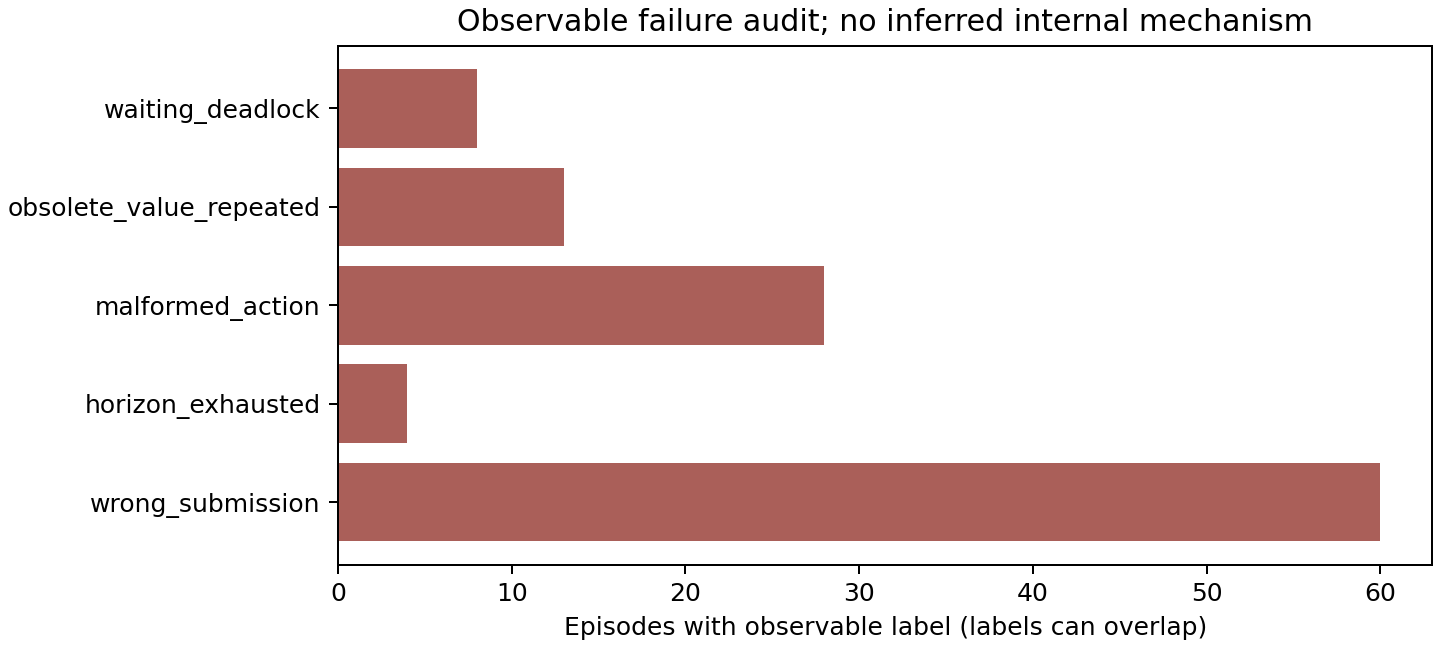

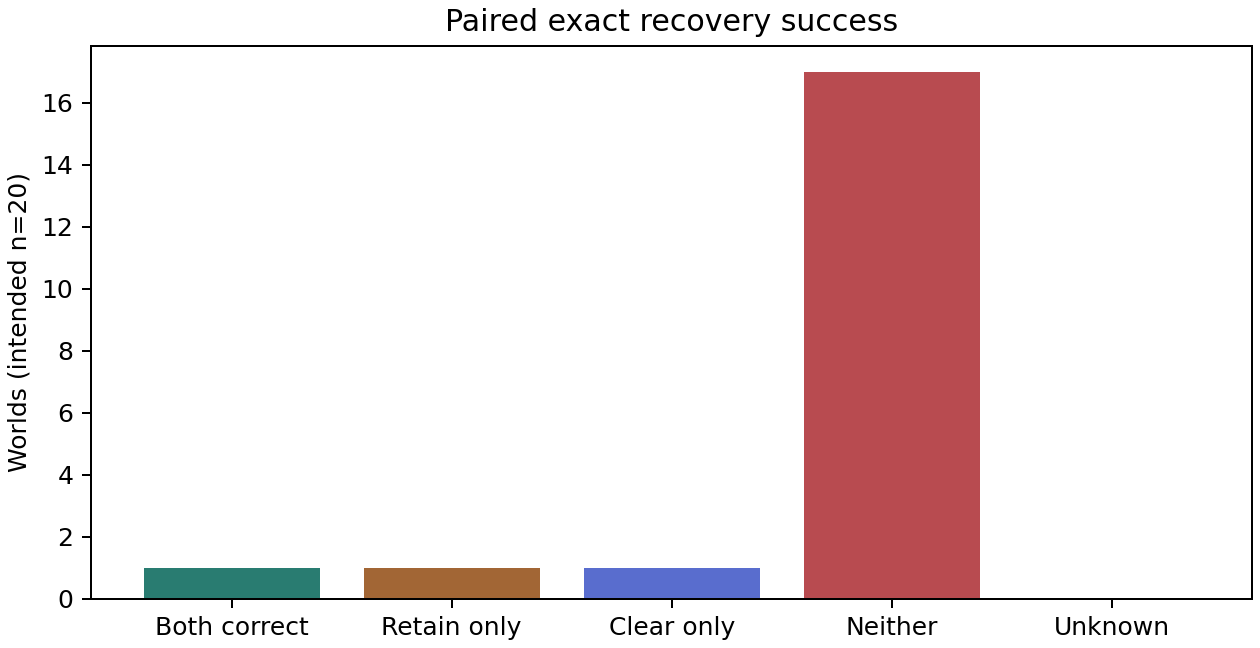

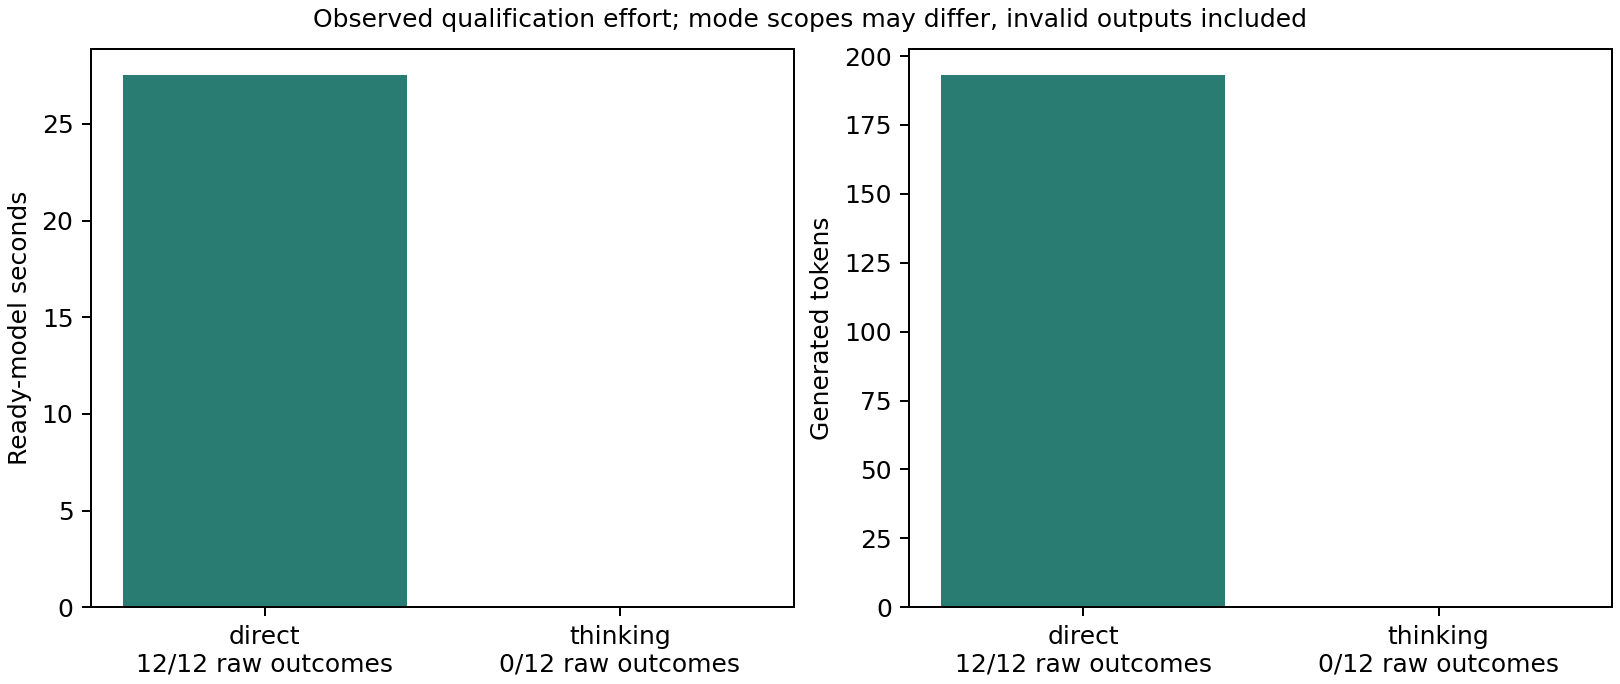

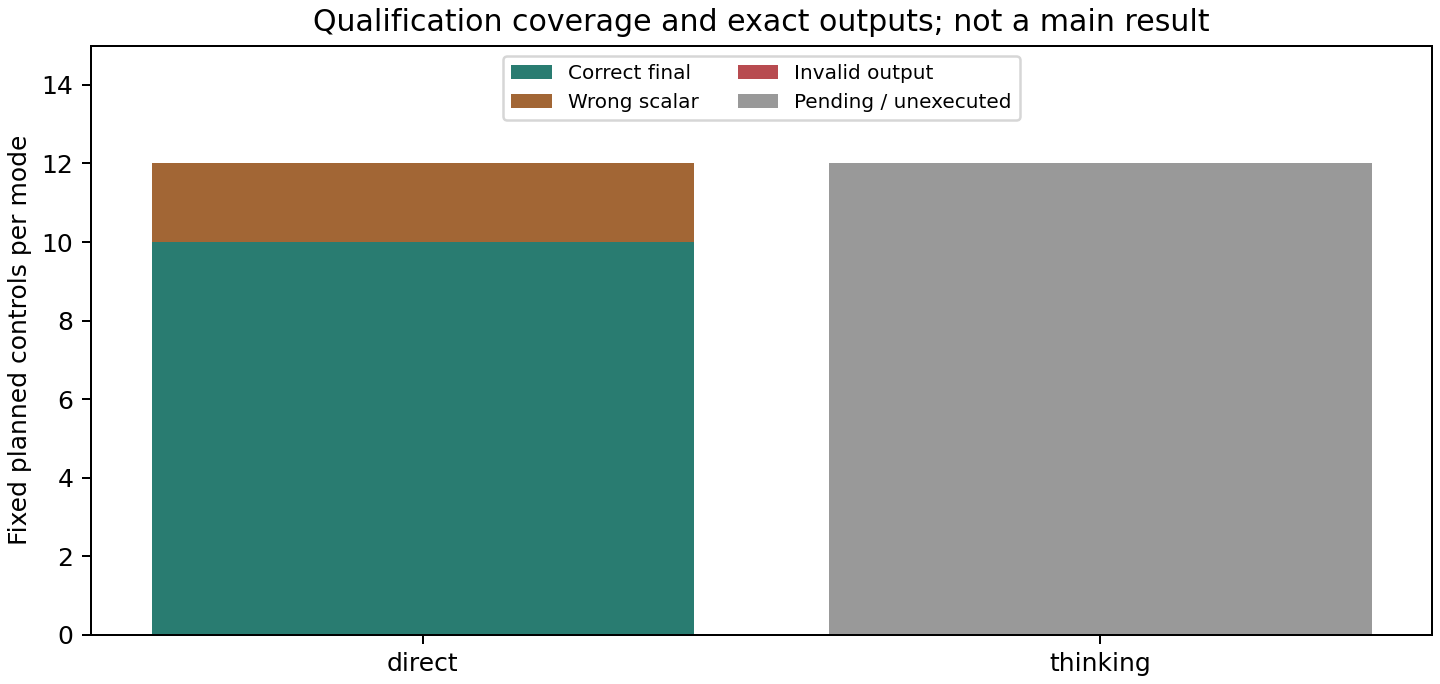

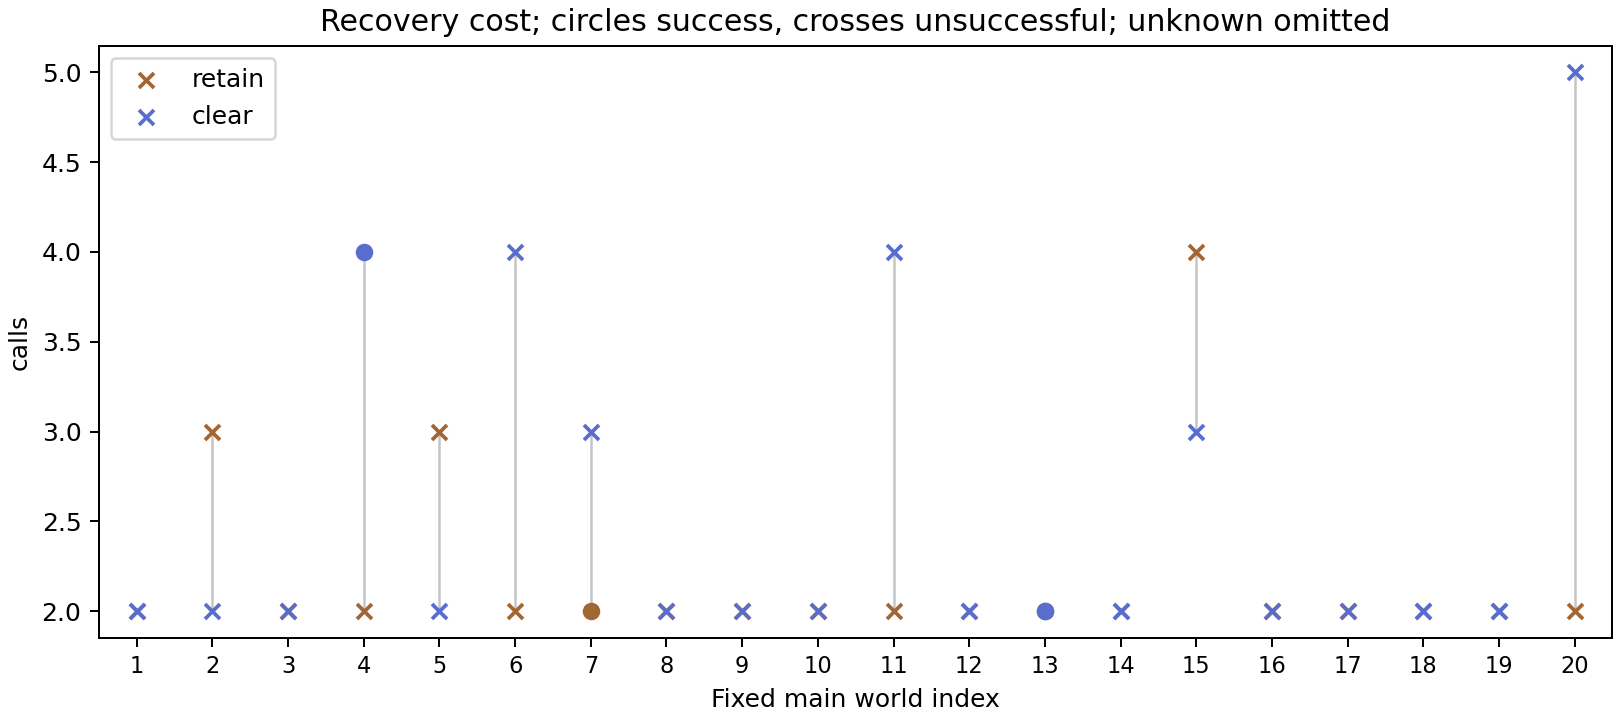

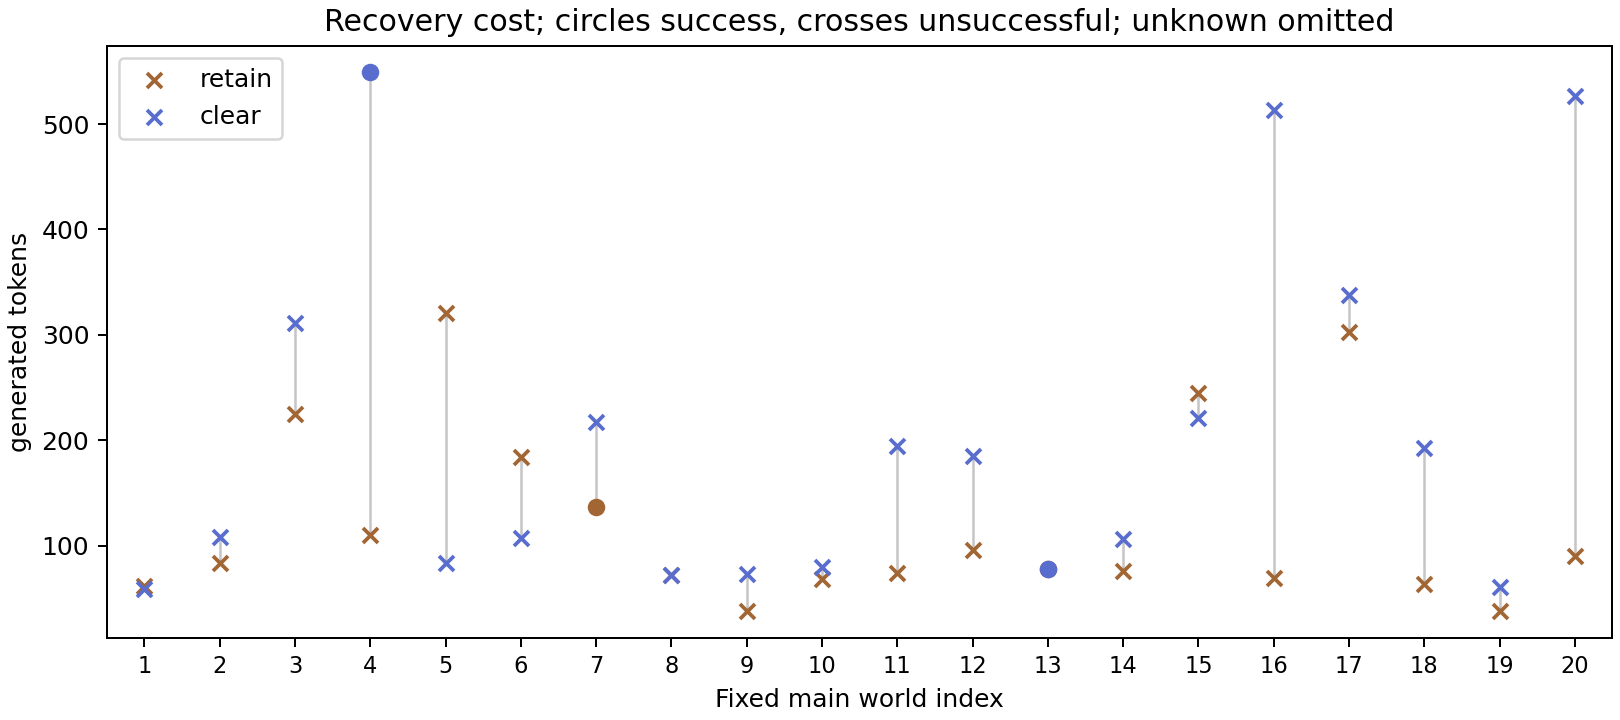

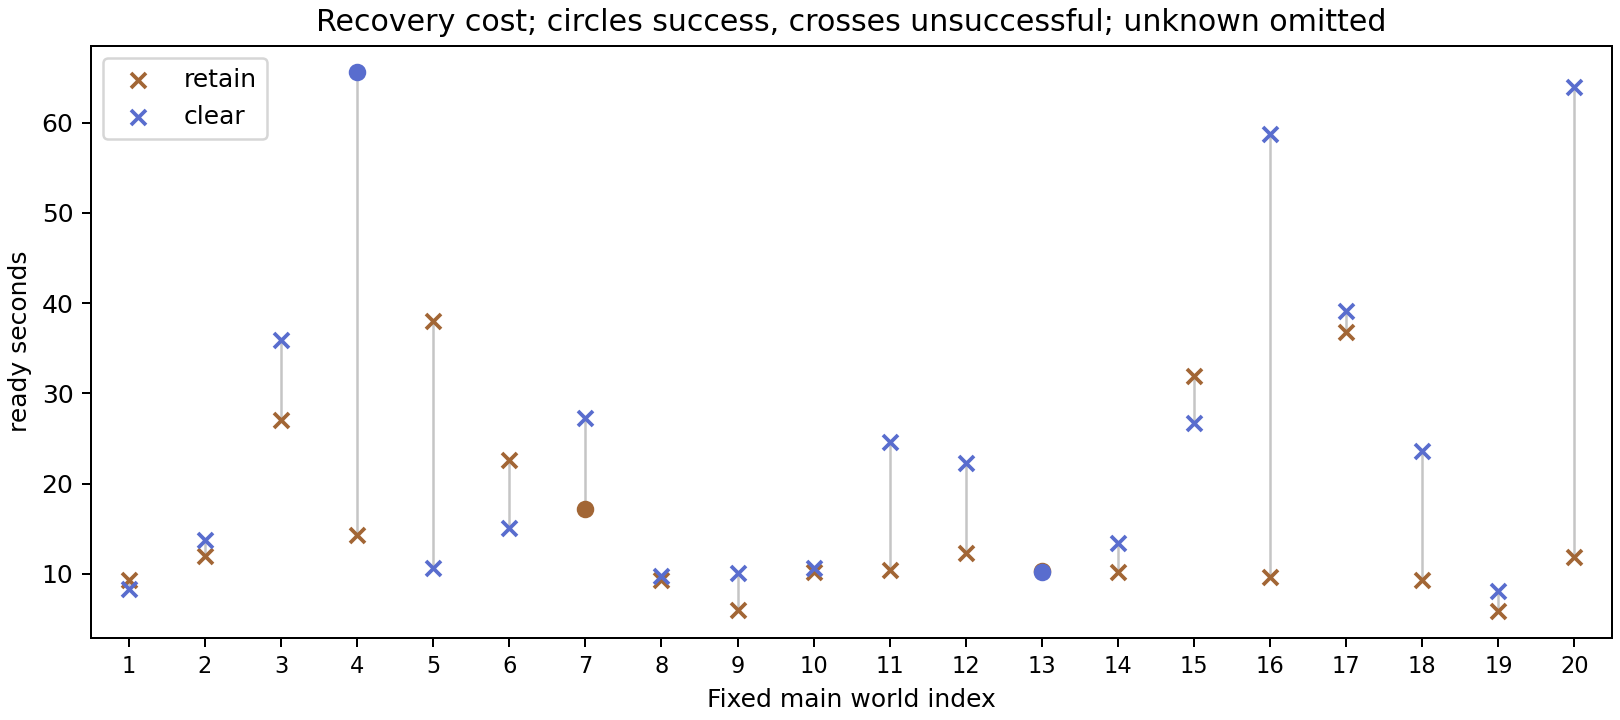

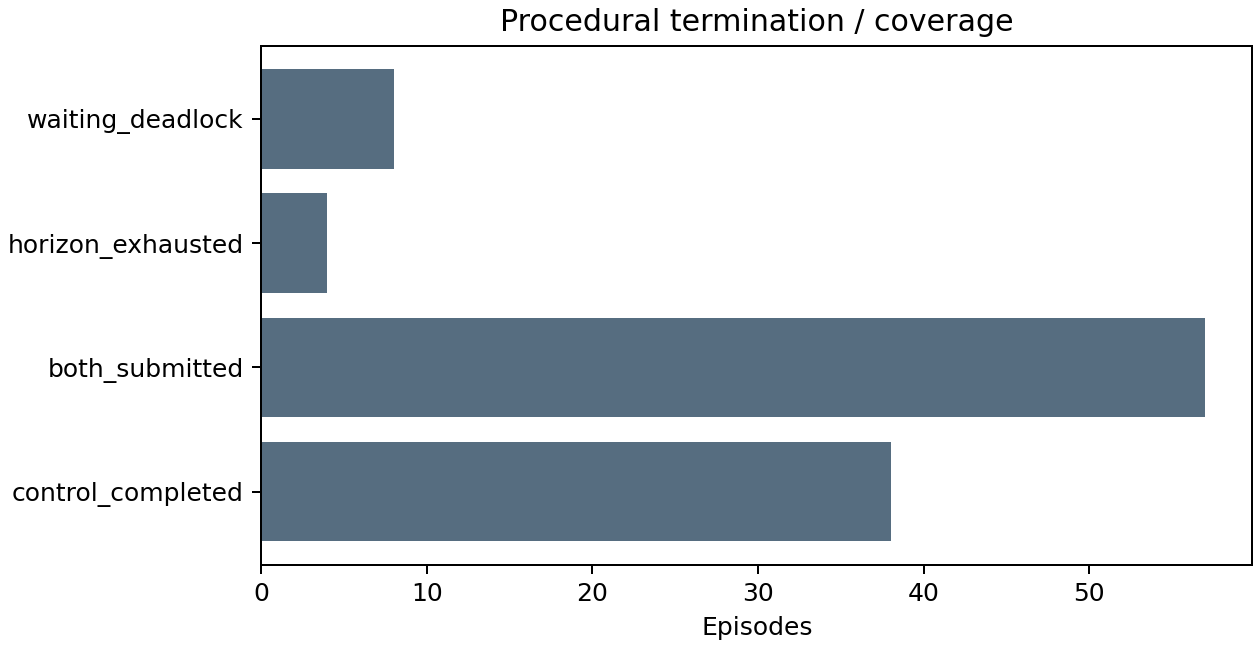

In [31]:
study.build_report();


## Verify the portable checkpoint and download results

Quiescent cumulative ZIP and exact read-only fresh-directory reconstruction. Download latest.zip and the executed notebook. Checkpoints happen automatically even if you ignore their links during execution.


In [32]:
study.save_checkpoint(verify=True);


Checkpoint action/snapshot: 2,877,065 bytes; integrity passed
snapshot: complete · checkpoint /kaggle/working/i01-outcomes-study/exports/latest.zip


Measurement,Recorded value
Boundary requested,operator-snapshot


Checkpoint: passed


Measurement,Recorded value
Integrity,passed
Attempts,252
Boundary,action/snapshot
Reconstruction,exact outcomes/costs/traces/gates match archived analysis
Model attempts,0


## Close model workers and controller

Close after final export; the closing checkpoint retains actual process evidence. Stop Kaggle through its UI to release its allocation. Process closure and a link do not prove provider deallocation or an external download.


In [33]:
study.finish_session();


Checkpoint close-models: 2,878,098 bytes; integrity passed


Checkpoint controller-close: 2,878,097 bytes; integrity passed
Controller output closed; process exit is not yet confirmed


Measurement,Recorded value
Processes closed,Yes
Provider release,Stop Kaggle through its UI; process exit alone does not prove deallocation.


## Results, errors and later restoration

The cumulative checkpoint is **/kaggle/working/i01-outcomes-study/exports/latest.zip**;
reports, all conversations/raw outcomes, CSV tables and figures are under
**/kaggle/working/i01-outcomes-study/reports/**. Download them and the executed
notebook outside the session. Save existing output without another inference run.

A real prerequisite failure stops further admission, attempts a settled partial export, closes workers with recorded acknowledgements and keeps the last valid
archive plus receipts. A provider hard shutdown may occur before a new export;
no missing outcome or unbounded spending is silently assumed zero. Checkpoints
are already present; a convenient restore workflow can be added later without
having to reconstruct unsaved hours of work.

For inspection with intact files (copy only the needed commands into a cell):

    study.show_status();
    study.inspect(audit_limit=None);  # Every raw call, no display limit.
    study.links(all_files=True);
    study.build_report();  # Works read-only after controller closure.

Before closure, interrupt requests pause; wait for admitted calls to settle:

    study.pause();
    study.save_checkpoint(verify=True);
    study.finish_session();

For a later session, use this checkpoint's exact source and the existing explicit
restore/reopen commands in **docs/I01_KAGGLE.md**. Supply actual prior-exit/tail
and current-time facts. New loaded replicas require two charged reload probes;
do not repeat completed controls, pilot outcomes or earlier numbered batches.
Do not rerun the complete notebook to bypass a failed gate or reset its budget.

After execution, inspect all pilot/main conversations and add genuine human
annotations using the frozen rubric and exact call references. Automatic checks
establish evidence/protocol/resource eligibility, not meaningful communication,
human understanding, download completion or a favorable scientific effect.
